In [ ]:
!pip install -q flask numpy scipy networkx scikit-fuzzy pandas openpyxl matplotlib
!mkdir -p boiler_fuzzy_web/templates boiler_fuzzy_web/static boiler_fuzzy_web/exports
%cd boiler_fuzzy_web

/content/boiler_fuzzy_web


In [ ]:
%%writefile fuzzy_controller.py
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

TERMS = ["NB", "NS", "ZE", "PS", "PB"]

class FuzzyBoilerController:
    def __init__(self):
        self.error_univ = np.linspace(-30, 30, 301)
        self.rate_univ = np.linspace(-2, 2, 301)
        self.action_univ = np.linspace(-10, 10, 301)

        self.error = ctrl.Antecedent(self.error_univ, "error")
        self.rate = ctrl.Antecedent(self.rate_univ, "rate")
        self.action = ctrl.Consequent(self.action_univ, "action")

        self.error.automf(names=TERMS)
        self.rate.automf(names=TERMS)
        self.action.automf(names=TERMS)

        # матриця 5x5
        rule_matrix = [
            ["NB", "NB", "NB", "NB", "NS"],  # error = NB (дуже гаряче)
            ["NS", "NS", "NS", "ZE", "ZE"],  # error = NS
            ["PS", "PS", "ZE", "NS", "NS"],  # error = ZE (біля завдання)
            ["PB", "PS", "PS", "ZE", "ZE"],  # error = PS
            ["PB", "PB", "PB", "PS", "PS"],  # error = PB (дуже холодно)
        ]

        rules = []
        for i, e_term in enumerate(TERMS):
            for j, r_term in enumerate(TERMS):
                out_term = rule_matrix[i][j]
                rules.append(ctrl.Rule(self.error[e_term] & self.rate[r_term], self.action[out_term]))

        self.system = ctrl.ControlSystem(rules)
        self.sim = ctrl.ControlSystemSimulation(self.system)

    def compute(self, error_val, rate_val):
        e_clipped = float(np.clip(error_val, -30.0, 30.0))
        r_clipped = float(np.clip(rate_val, -2.0, 2.0))
        self.sim.input["error"] = e_clipped
        self.sim.input["rate"] = r_clipped
        self.sim.compute()
        return float(self.sim.output["action"])

Writing fuzzy_controller.py


In [ ]:
%%writefile pid_controller.py
import numpy as np

class PIDController:
    def __init__(self, kp=1.2, ki=0.04, kd=8.0, out_min=0.0, out_max=100.0):
        self.kp = kp
        self.ki = ki
        self.kd = kd
        self.out_min = out_min
        self.out_max = out_max
        self.integral = 0.0
        self.prev_error = None

    def compute(self, error, dt):
        p = self.kp * error
        self.integral = np.clip(self.integral + error * dt, -500.0, 500.0)
        i = self.ki * self.integral
        d = 0.0 if self.prev_error is None else self.kd * (error - self.prev_error) / dt
        self.prev_error = error
        u = p + i + d
        return float(np.clip(u, self.out_min, self.out_max))

Writing pid_controller.py


In [ ]:
%%writefile simulation.py
import numpy as np
from fuzzy_controller import FuzzyBoilerController
from pid_controller import PIDController

def calc_metrics(time_arr, temp_arr, setpoint, dt):
    temp = np.array(temp_arr)
    err = setpoint - temp
    overshoot = max(0.0, float((np.max(temp) - setpoint) / setpoint * 100.0))
    steady_error = float(abs(err[-1]))
    iae = float(np.sum(np.abs(err)) * dt)
    ise = float(np.sum(err ** 2) * dt)

    # час входження в зону допуску +-2 °C
    settling_time = None
    in_band = np.abs(err) <= 2.0
    for idx in range(len(time_arr)):
        if np.all(in_band[idx:]):
            settling_time = round(float(time_arr[idx]), 1)
            break

    return {
        "overshoot": round(overshoot, 2),
        "settling_time": settling_time if settling_time is not None else "Не досягнуто",
        "steady_error": round(steady_error, 2),
        "iae": round(iae, 1),
        "ise": round(ise, 1),
    }

def run_comparison(setpoint=180.0, initial=140.0, duration=600, dt=2.0, tau=80.0, disturbance=15.0):
    steps = int(duration / dt) + 1
    time_arr = [round(k * dt, 1) for k in range(steps)]
    setpoint_arr = [setpoint] * steps

    fuzzy_ctrl = FuzzyBoilerController()
    pid_ctrl = PIDController()

    t_fuzzy, u_fuzzy = [initial], [30.0]
    t_pid, u_pid = [initial], [30.0]

    for k in range(steps - 1):
        # збурення
        d_val = disturbance if time_arr[k] >= duration * 0.5 else 0.0

        # нечіткий регулятор
        err_f = setpoint - t_fuzzy[-1]
        rate_f = 0.0 if k == 0 else (t_fuzzy[-1] - t_fuzzy[-2]) / (dt / 60.0)
        du = fuzzy_ctrl.compute(err_f, rate_f)
        new_uf = float(np.clip(u_fuzzy[-1] + du, 0.0, 100.0))
        t_eq_f = 20.0 + 2.2 * new_uf
        next_tf = t_fuzzy[-1] + (dt / tau) * (t_eq_f - t_fuzzy[-1]) - (dt / tau) * d_val
        u_fuzzy.append(round(new_uf, 2))
        t_fuzzy.append(round(float(next_tf), 2))

        # ПІД-регулятор
        err_p = setpoint - t_pid[-1]
        new_up = pid_ctrl.compute(err_p, dt)
        t_eq_p = 20.0 + 2.2 * new_up
        next_tp = t_pid[-1] + (dt / tau) * (t_eq_p - t_pid[-1]) - (dt / tau) * d_val
        u_pid.append(round(new_up, 2))
        t_pid.append(round(float(next_tp), 2))

    return {
        "time": time_arr,
        "setpoint": setpoint_arr,
        "fuzzy_temperature": t_fuzzy,
        "pid_temperature": t_pid,
        "fuzzy_valve": u_fuzzy,
        "pid_valve": u_pid,
        "metrics": {
            "fuzzy": calc_metrics(time_arr, t_fuzzy, setpoint, dt),
            "pid": calc_metrics(time_arr, t_pid, setpoint, dt),
        },
    }

Writing simulation.py


In [ ]:
%%writefile export_service.py
import pandas as pd

def build_dataframe(result):
    return pd.DataFrame({
        "Час, с": result["time"],
        "Задана температура, °C": result["setpoint"],
        "Нечіткий регулятор, °C": result["fuzzy_temperature"],
        "ПІД-регулятор, °C": result["pid_temperature"],
        "Клапан нечіткий, %": result["fuzzy_valve"],
        "Клапан ПІД, %": result["pid_valve"],
    })

def export_csv(result, filename):
    build_dataframe(result).to_csv(filename, index=False, encoding="utf-8-sig")

def export_excel(result, filename):
    df = build_dataframe(result)
    metrics_df = pd.DataFrame([
        {"Регулятор": "Нечіткий (Мамдані)", **result["metrics"]["fuzzy"]},
        {"Регулятор": "ПІД-регулятор", **result["metrics"]["pid"]},
    ])
    with pd.ExcelWriter(filename, engine="openpyxl") as writer:
        df.to_excel(writer, sheet_name="Перехідний процес", index=False)
        metrics_df.to_excel(writer, sheet_name="Метрики", index=False)

Writing export_service.py


In [ ]:
%%writefile app.py
from flask import Flask, render_template, request, jsonify, send_file
from simulation import run_comparison
from export_service import export_csv, export_excel

app = Flask(__name__)
LAST_RESULT = None

@app.get("/")
def index():
    return render_template("index.html")

@app.post("/api/simulate")
def simulate():
    global LAST_RESULT
    data = request.get_json(silent=True) or {}
    try:
        setpoint = float(data.get("setpoint", 180))
        initial = float(data.get("initial", 140))
        duration = int(data.get("duration", 600))
        disturbance = float(data.get("disturbance", 15))
        if not (50 <= setpoint <= 300 and 10 <= initial <= 250 and 60 <= duration <= 3600):
            return jsonify({"error": "Параметри виходять за допустимі межі"}), 400
        LAST_RESULT = run_comparison(setpoint, initial, duration, disturbance=disturbance)
        return jsonify(LAST_RESULT)
    except (TypeError, ValueError) as exc:
        return jsonify({"error": str(exc)}), 400

@app.get("/api/export/<fmt>")
def export_data(fmt):
    if LAST_RESULT is None:
        return jsonify({"error": "Спочатку запустіть моделювання"}), 400
    if fmt == "csv":
        path = "exports/boiler_simulation.csv"
        export_csv(LAST_RESULT, path)
        return send_file(path, as_attachment=True)
    if fmt == "xlsx":
        path = "exports/boiler_simulation.xlsx"
        export_excel(LAST_RESULT, path)
        return send_file(path, as_attachment=True)
    return jsonify({"error": "Невідомий формат"}), 400

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

Writing app.py


In [ ]:
%%writefile templates/index.html
<!DOCTYPE html>
<html lang="uk">
<head>
    <meta charset="UTF-8">
    <title>Моделювання нечіткого регулятора котла</title>
    <script src="https://cdn.jsdelivr.net/npm/chart.js"></script>
    <style>
        body { font-family: Arial, sans-serif; background: #f1f5f9; margin: 0; color: #1e293b; }
        header { background: #0f172a; color: #fff; padding: 14px 24px; font-size: 18px; font-weight: bold; }
        .container { max-width: 1200px; margin: 20px auto; padding: 0 16px; display: grid; grid-template-columns: 320px 1fr; gap: 20px; }
        .card { background: #fff; padding: 18px; border-radius: 8px; box-shadow: 0 2px 6px rgba(0,0,0,0.08); margin-bottom: 16px; }
        label { display: block; font-size: 13px; font-weight: bold; margin-top: 10px; }
        input { width: 100%; padding: 7px; margin-top: 4px; border: 1px solid #cbd5e1; border-radius: 4px; box-sizing: border-box; }
        button { width: 100%; padding: 10px; margin-top: 14px; background: #2563eb; color: #fff; border: none; border-radius: 5px; cursor: pointer; font-weight: bold; }
        button:hover { background: #1d4ed8; }
        .btn-sec { background: #059669; margin-top: 8px; }
        table { width: 100%; border-collapse: collapse; font-size: 13px; margin-top: 10px; }
        th, td { border: 1px solid #e2e8f0; padding: 8px; text-align: center; }
        th { background: #f8fafc; }
    </style>
</head>
<body>
<header>Нечіткий регулятор температури та подачі палива в котлі (Flask)</header>
<div class="container">
    <div>
        <div class="card">
            <h3>Параметри котла</h3>
            <label>Задана температура Tзад (°C):</label>
            <input type="number" id="setpoint" value="180">
            <label>Початкова температура (°C):</label>
            <input type="number" id="initial" value="140">
            <label>Тривалість симуляції (с):</label>
            <input type="number" id="duration" value="600">
            <label>Збурення на половині часу (°C):</label>
            <input type="number" id="disturbance" value="15">
            <button onclick="runSimulation()">Запустити моделювання</button>
            <button class="btn-sec" onclick="window.location='/api/export/csv'">Завантажити CSV</button>
            <button class="btn-sec" onclick="window.location='/api/export/xlsx'">Завантажити Excel (XLSX)</button>
        </div>

        <div class="card">
            <h3>Метрики якості</h3>
            <table>
                <thead><tr><th>Показник</th><th>Нечіткий</th><th>ПІД</th></tr></thead>
                <tbody id="metrics-body">
                    <tr><td>Перерегулювання, %</td><td id="f-ov">-</td><td id="p-ov">-</td></tr>
                    <tr><td>Час регулювання, с</td><td id="f-st">-</td><td id="p-st">-</td></tr>
                    <tr><td>Усталена похибка, °C</td><td id="f-se">-</td><td id="p-se">-</td></tr>
                    <tr><td>IAE</td><td id="f-iae">-</td><td id="p-iae">-</td></tr>
                    <tr><td>ISE</td><td id="f-ise">-</td><td id="p-ise">-</td></tr>
                </tbody>
            </table>
        </div>
    </div>

    <div>
        <div class="card"><canvas id="tempChart" height="115"></canvas></div>
        <div class="card"><canvas id="valveChart" height="95"></canvas></div>
    </div>
</div>

<script>
let tempChart, valveChart;

async function runSimulation() {
    const payload = {
        setpoint: Number(document.getElementById("setpoint").value),
        initial: Number(document.getElementById("initial").value),
        duration: Number(document.getElementById("duration").value),
        disturbance: Number(document.getElementById("disturbance").value),
    };
    const res = await fetch("/api/simulate", {
        method: "POST",
        headers: {"Content-Type": "application/json"},
        body: JSON.stringify(payload)
    });
    const data = await res.json();
    if (!res.ok) { alert(data.error || "Помилка"); return; }

    const mf = data.metrics.fuzzy, mp = data.metrics.pid;
    document.getElementById("f-ov").textContent = mf.overshoot;
    document.getElementById("p-ov").textContent = mp.overshoot;
    document.getElementById("f-st").textContent = mf.settling_time;
    document.getElementById("p-st").textContent = mp.settling_time;
    document.getElementById("f-se").textContent = mf.steady_error;
    document.getElementById("p-se").textContent = mp.steady_error;
    document.getElementById("f-iae").textContent = mf.iae;
    document.getElementById("p-iae").textContent = mp.iae;
    document.getElementById("f-ise").textContent = mf.ise;
    document.getElementById("p-ise").textContent = mp.ise;

    if (tempChart) tempChart.destroy();
    tempChart = new Chart(document.getElementById("tempChart"), {
        type: "line",
        data: {
            labels: data.time,
            datasets: [
                { label: "Задана температура, °C", data: data.setpoint, borderColor: "#64748b", borderDash: [5,5], pointRadius: 0 },
                { label: "Нечіткий регулятор, °C", data: data.fuzzy_temperature, borderColor: "#2563eb", pointRadius: 0 },
                { label: "ПІД-регулятор, °C", data: data.pid_temperature, borderColor: "#dc2626", pointRadius: 0 }
            ]
        },
        options: { plugins: { title: { display: true, text: "Перехідний процес температури в котлі" } } }
    });

    if (valveChart) valveChart.destroy();
    valveChart = new Chart(document.getElementById("valveChart"), {
        type: "line",
        data: {
            labels: data.time,
            datasets: [
                { label: "Клапан нечіткий, %", data: data.fuzzy_valve, borderColor: "#2563eb", pointRadius: 0 },
                { label: "Клапан ПІД, %", data: data.pid_valve, borderColor: "#dc2626", pointRadius: 0 }
            ]
        },
        options: { plugins: { title: { display: true, text: "Керувальний вплив (відкриття паливного клапана)" } } }
    });
}
window.onload = runSimulation;
</script>
</body>
</html>

Writing templates/index.html


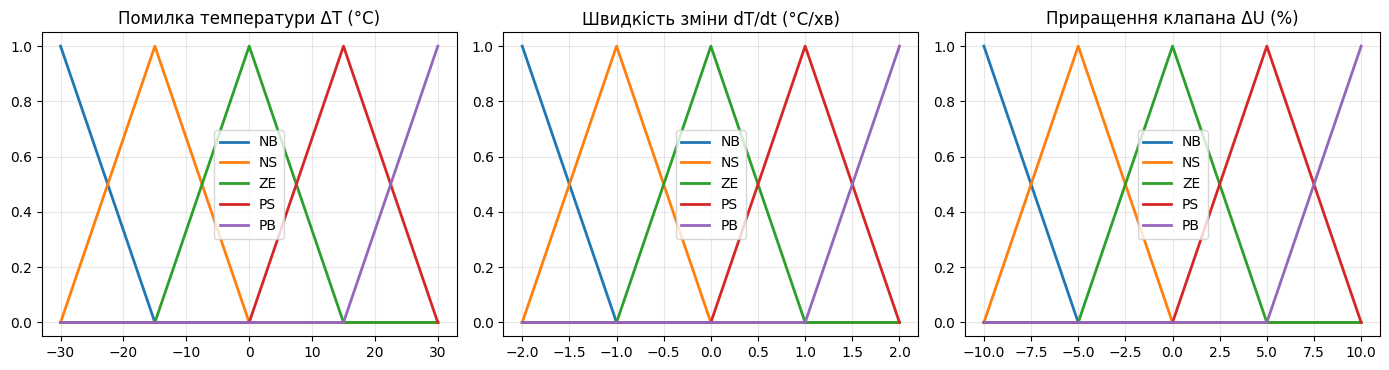

In [ ]:
import matplotlib.pyplot as plt
from fuzzy_controller import FuzzyBoilerController

fc = FuzzyBoilerController()
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
items = [
    (fc.error, fc.error_univ, "Помилка температури ΔT (°C)"),
    (fc.rate, fc.rate_univ, "Швидкість зміни dT/dt (°C/хв)"),
    (fc.action, fc.action_univ, "Приращення клапана ΔU (%)"),
]
for ax, (var, univ, title) in zip(axes, items):
    for term in var.terms:
        ax.plot(univ, var[term].mf, linewidth=2, label=term)
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import subprocess, time
from google.colab import output

server = subprocess.Popen(["python", "app.py"])
time.sleep(2)
output.serve_kernel_port_as_window(5000)

Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>